## 1. Loading Official Test Datasets

Load the official Mass and Calcification test datasets.
These datasets will be used to evaluate the previously trained models.

In [5]:
import pandas as pd
import numpy as np
import joblib
import os

mass_df = pd.read_csv(
    "../data/mass_case_description_test_set.csv"
)

calc_df = pd.read_csv(
    "../data/calc_case_description_test_set.csv"
)

print("Mass test shape:", mass_df.shape)
print("Calcification test shape:", calc_df.shape)

Mass test shape: (378, 14)
Calcification test shape: (326, 14)


## 2. Data Cleaning and Standardization

Apply the same missing-value treatment and category
standardization used during the training phase.

In [6]:
# Mass dataset

mass_df = mass_df.copy()

mass_df["mass shape"] = (
    mass_df["mass shape"].fillna("UNKNOWN")
)

mass_df["mass margins"] = (
    mass_df["mass margins"].fillna("UNKNOWN")
)


# Calcification dataset

calc_df = calc_df.copy()

calc_df["calc type"] = (
    calc_df["calc type"].fillna("UNKNOWN")
)

calc_df["calc distribution"] = (
    calc_df["calc distribution"].fillna("UNKNOWN")
)


# Normalize Calcification categories

calc_df["calc type"] = (
    calc_df["calc type"]
    .str.replace(
        "LUCENT_CENTERED",
        "LUCENT_CENTER",
        regex=False
    )
    .str.replace(
        "PLEOMORPHIC-PLEOMORPHIC",
        "PLEOMORPHIC",
        regex=False
    )
)

calc_df["calc distribution"] = (
    calc_df["calc distribution"]
    .replace({
        "REGIONAL-REGIONAL": "REGIONAL"
    })
)

print("Mass missing values:")
print(mass_df[["mass shape", "mass margins"]].isnull().sum())

print("\nCalcification missing values:")
print(calc_df[["calc type", "calc distribution"]].isnull().sum())

print("\nCleaning completed.")

Mass missing values:
mass shape      0
mass margins    0
dtype: int64

Calcification missing values:
calc type            0
calc distribution    0
dtype: int64

Cleaning completed.


## 3. Feature Selection and Target Separation

Select the same input features used during training.
Separate the target variable (`pathology`) and patient identifiers.

In [9]:
# Standardize Calcification column name

calc_df = calc_df.rename(
    columns={"breast density": "breast_density"}
)


# Feature selection

mass_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins",
    "assessment",
    "subtlety"
]

calc_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution",
    "assessment",
    "subtlety"
]


# Separate features and target

mass_X_official = mass_df[mass_features].copy()
calc_X_official = calc_df[calc_features].copy()

mass_y_official = mass_df["pathology"].copy()
calc_y_official = calc_df["pathology"].copy()


# Preserve patient identifiers

mass_patient_official = mass_df["patient_id"].copy()
calc_patient_official = calc_df["patient_id"].copy()


# Display results

print("Mass features:", mass_X_official.shape)
print("Calcification features:", calc_X_official.shape)

print("\nMass target distribution:")
print(mass_y_official.value_counts())

print("\nCalcification target distribution:")
print(calc_y_official.value_counts())

Mass features: (378, 7)
Calcification features: (326, 7)

Mass target distribution:
pathology
BENIGN                     194
MALIGNANT                  147
BENIGN_WITHOUT_CALLBACK     37
Name: count, dtype: int64

Calcification target distribution:
pathology
BENIGN                     130
MALIGNANT                  129
BENIGN_WITHOUT_CALLBACK     67
Name: count, dtype: int64


## 4. Applying Saved Preprocessing Objects

Load the preprocessing objects fitted on the training datasets.
Transform the official test features without fitting again.

In [10]:
mass_preprocessor = joblib.load(
    "../models/mass_preprocessor.joblib"
)

calc_preprocessor = joblib.load(
    "../models/calc_preprocessor.joblib"
)


mass_X_official_encoded = mass_preprocessor.transform(
    mass_X_official
)

calc_X_official_encoded = calc_preprocessor.transform(
    calc_X_official
)


print("Mass encoded shape:",
      mass_X_official_encoded.shape)

print("Calcification encoded shape:",
      calc_X_official_encoded.shape)

Mass encoded shape: (378, 40)
Calcification encoded shape: (326, 52)


## 5. Target Label Encoding

Convert pathology labels into numerical values using
the same mapping applied during training.

In [11]:
pathology_mapping = {
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 1,
    "MALIGNANT": 2
}

mass_y_official_encoded = (
    mass_y_official.map(pathology_mapping)
)

calc_y_official_encoded = (
    calc_y_official.map(pathology_mapping)
)

assert mass_y_official_encoded.notna().all()
assert calc_y_official_encoded.notna().all()

mass_y_official_encoded = (
    mass_y_official_encoded.astype(int)
)

calc_y_official_encoded = (
    calc_y_official_encoded.astype(int)
)

print("Mass target classes:",
      sorted(mass_y_official_encoded.unique()))

print("Calcification target classes:",
      sorted(calc_y_official_encoded.unique()))

print("\nTarget encoding completed.")

Mass target classes: [np.int64(0), np.int64(1), np.int64(2)]
Calcification target classes: [np.int64(0), np.int64(1), np.int64(2)]

Target encoding completed.


## 6. Loading Trained Classification Models

Load the four previously trained models.
No additional training will be performed.

In [12]:
models = {
    "Mass": {
        "Logistic Regression": joblib.load(
            "../models/mass_logistic_regression.joblib"
        ),
        "Random Forest": joblib.load(
            "../models/mass_random_forest.joblib"
        )
    },
    "Calcification": {
        "Logistic Regression": joblib.load(
            "../models/calc_logistic_regression.joblib"
        ),
        "Random Forest": joblib.load(
            "../models/calc_random_forest.joblib"
        )
    }
}

print("All four classification models loaded successfully.")

All four classification models loaded successfully.


## 7. Official Test Evaluation

Evaluate the trained models using the official test datasets.
Calculate accuracy, macro precision, macro recall and macro F1-score.

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

datasets = {
    "Mass": (
        mass_X_official_encoded,
        mass_y_official_encoded
    ),
    "Calcification": (
        calc_X_official_encoded,
        calc_y_official_encoded
    )
}

for dataset_name, (X_test, y_test) in datasets.items():

    for model_name, model in models[dataset_name].items():

        y_pred = model.predict(X_test)

        evaluation_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "F1-score": f1_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            )
        })

official_evaluation_df = pd.DataFrame(evaluation_results)

print (official_evaluation_df.round(3))

         Dataset                Model  Accuracy  Precision  Recall  F1-score
0           Mass  Logistic Regression     0.725      0.781   0.671     0.699
1           Mass        Random Forest     0.741      0.699   0.692     0.694
2  Calcification  Logistic Regression     0.702      0.757   0.745     0.742
3  Calcification        Random Forest     0.733      0.773   0.769     0.770


## 8. Official Test Confusion Matrices

Visualize the confusion matrices of the four trained models
to analyze their classification errors across the three pathology classes.

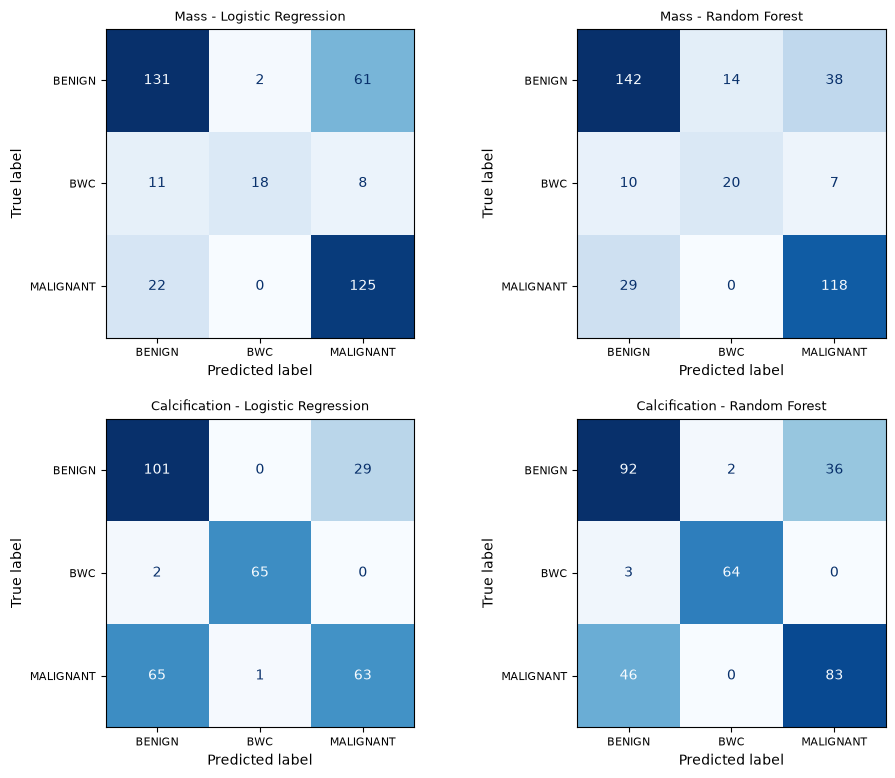

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

datasets = [
    ("Mass", mass_X_official_encoded, mass_y_official_encoded),
    ("Calcification", calc_X_official_encoded, calc_y_official_encoded)
]

labels = [0, 1, 2]

display_labels = [
    "BENIGN",
    "BWC",
    "MALIGNANT"
]

for i, (dataset_name, X_test, y_test) in enumerate(datasets):

    for j, (model_name, model) in enumerate(
        models[dataset_name].items()
    ):

        y_pred = model.predict(X_test)

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=labels
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=display_labels
        )

        disp.plot(
            ax=axes[i, j],
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        axes[i, j].set_title(
            f"{dataset_name} - {model_name}",
            fontsize=9
        )

        axes[i, j].tick_params(
            axis="both",
            labelsize=8
        )

plt.tight_layout(pad=1.5)
plt.show()

In [18]:
from sklearn.metrics import classification_report

target_names = [
    "BENIGN",
    "BENIGN_WITHOUT_CALLBACK",
    "MALIGNANT"
]

for dataset_name, X_test, y_test in datasets:

    print(f"\n{'=' * 60}")
    print(f"{dataset_name} - Classification Reports")
    print("=" * 60)

    for model_name, model in models[dataset_name].items():

        y_pred = model.predict(X_test)

        print(f"\n{model_name}")
        print("-" * 40)

        print(classification_report(
            y_test,
            y_pred,
            labels=[0, 1, 2],
            target_names=target_names,
            zero_division=0
        ))


Mass - Classification Reports

Logistic Regression
----------------------------------------
                         precision    recall  f1-score   support

                 BENIGN       0.80      0.68      0.73       194
BENIGN_WITHOUT_CALLBACK       0.90      0.49      0.63        37
              MALIGNANT       0.64      0.85      0.73       147

               accuracy                           0.72       378
              macro avg       0.78      0.67      0.70       378
           weighted avg       0.75      0.72      0.72       378


Random Forest
----------------------------------------
                         precision    recall  f1-score   support

                 BENIGN       0.78      0.73      0.76       194
BENIGN_WITHOUT_CALLBACK       0.59      0.54      0.56        37
              MALIGNANT       0.72      0.80      0.76       147

               accuracy                           0.74       378
              macro avg       0.70      0.69      0.69       378
 

## Patient-Level Data Leakage Check

Verify that no patient appears in both the original training dataset and the official test dataset.

In [19]:
mass_train_ids = pd.read_csv(
    "../data/mass_case_description_train_set.csv"
)["patient_id"]

calc_train_ids = pd.read_csv(
    "../data/calc_case_description_train_set.csv"
)["patient_id"]

mass_overlap = set(mass_train_ids) & set(mass_patient_official)
calc_overlap = set(calc_train_ids) & set(calc_patient_official)

print("Mass patient overlap:", len(mass_overlap))
print("Calcification patient overlap:", len(calc_overlap))

assert len(mass_overlap) == 0, "Mass patient overlap detected!"
assert len(calc_overlap) == 0, "Calcification patient overlap detected!"

print("\nNo patient overlap detected.")

Mass patient overlap: 0
Calcification patient overlap: 0

No patient overlap detected.
